# Vectors and Linear Algebra

A **vector** $\mathbf{v} \in \mathbb{R}^n$ is an ordered list of $n$ real numbers. In $\mathbb{R}^2$, $\mathbf{v} = (v_x, v_y)$ represents a directed segment from the origin to the point $(v_x, v_y)$.

**Scalar multiplication:** $\alpha\mathbf{v} = (\alpha v_x, \alpha v_y)$ scales the vector's length by $|\alpha|$ (and reverses direction if $\alpha < 0$).

**Magnitude (norm):** $\|\mathbf{v}\| = \sqrt{v_x^2 + v_y^2}$.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_vector(vx, vy, scale):
    sv = scale * np.array([vx, vy])
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.quiver(0, 0, vx, vy, angles='xy', scale_units='xy', scale=1,
              color='blue', lw=2, label=f'v = ({vx:.1f}, {vy:.1f})')
    ax.quiver(0, 0, sv[0], sv[1], angles='xy', scale_units='xy', scale=1,
              color='blue', alpha=0.4, lw=2, label=f'{scale:.1f}·v = ({sv[0]:.1f}, {sv[1]:.1f})')
    ax.set(xlim=(-6, 6), ylim=(-6, 6), aspect='equal', xlabel='x', ylabel='y')
    ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    mag = np.linalg.norm([vx, vy])
    ax.set_title(f'‖v‖ = {mag:.2f}   |   ‖{scale:.1f}·v‖ = {abs(scale)*mag:.2f}')
    plt.tight_layout(); plt.show()

wvx = widgets.FloatSlider(value=2, min=-5, max=5, step=0.1, description='vₓ')
wvy = widgets.FloatSlider(value=1, min=-5, max=5, step=0.1, description='vᵧ')
ws  = widgets.FloatSlider(value=1, min=-3, max=3, step=0.1, description='scale')
display(widgets.VBox([wvx, wvy, ws]),
        widgets.interactive_output(plot_vector, {'vx': wvx, 'vy': wvy, 'scale': ws}))


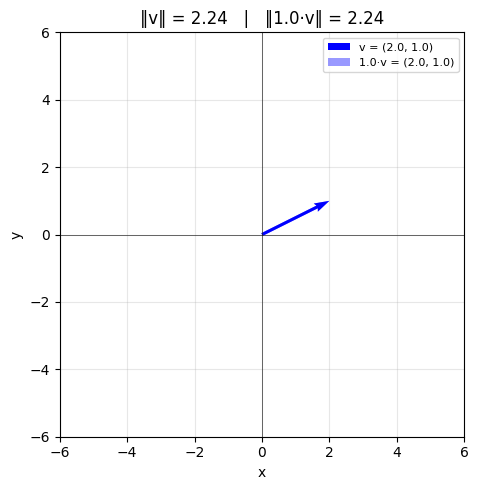

In [ ]:
# Hero figure — the one static image this notebook shows on GitHub.
plot_vector(vx=wvx.value, vy=wvy.value, scale=ws.value)

## Vector Addition and Subtraction

$$\mathbf{u} + \mathbf{v} = (u_x + v_x,\; u_y + v_y)$$

Geometrically: place $\mathbf{v}$'s tail at $\mathbf{u}$'s tip — the sum goes from the origin to $\mathbf{v}$'s tip (**parallelogram rule**).

Subtraction $\mathbf{v} - \mathbf{u}$ points from the tip of $\mathbf{u}$ to the tip of $\mathbf{v}$.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_sum(ux, uy, vx, vy):
    u = np.array([ux, uy]); v = np.array([vx, vy])
    s = u + v; d = v - u

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    kw = dict(angles='xy', scale_units='xy', scale=1)
    ax.quiver(0, 0, *u, color='blue', lw=2, label='u', **kw)
    ax.quiver(0, 0, *v, color='green', lw=2, label='v', **kw)
    ax.quiver(0, 0, *s, color='red', lw=2, label='u + v', **kw)
    # parallelogram ghost
    ax.quiver(*u, *v, color='green', alpha=0.3, **kw)
    ax.quiver(*v, *u, color='blue', alpha=0.3, **kw)
    # subtraction
    ax.quiver(*u, *d, color='black', alpha=0.6, lw=1.5, label='v − u', **kw)

    lim = max(np.abs([*u, *v, *s]).max(), 3) + 1
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal', xlabel='x', ylabel='y')
    ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_title(f'u + v = ({s[0]:.1f}, {s[1]:.1f})  |  v − u = ({d[0]:.1f}, {d[1]:.1f})')
    plt.tight_layout(); plt.show()

wux = widgets.FloatSlider(value=1, min=-4, max=4, step=0.1, description='uₓ')
wuy = widgets.FloatSlider(value=2, min=-4, max=4, step=0.1, description='uᵧ')
wvx = widgets.FloatSlider(value=2, min=-4, max=4, step=0.1, description='vₓ')
wvy = widgets.FloatSlider(value=1, min=-4, max=4, step=0.1, description='vᵧ')
ui = widgets.VBox([widgets.HBox([widgets.VBox([wux, wuy]), widgets.VBox([wvx, wvy])])])
display(ui, widgets.interactive_output(plot_sum, {'ux': wux, 'uy': wuy, 'vx': wvx, 'vy': wvy}))


## Dot Product

$$\mathbf{u} \cdot \mathbf{v} = u_x v_x + u_y v_y = \|\mathbf{u}\|\,\|\mathbf{v}\|\cos\theta$$

The dot product is a **scalar**. It measures how much one vector "goes in the direction" of the other.

**Projection** of $\mathbf{v}$ onto $\mathbf{u}$: $\text{proj}_{\mathbf{u}}\mathbf{v} = \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|^2}\,\mathbf{u}$.

$\mathbf{u} \cdot \mathbf{v} = 0 \iff \mathbf{u} \perp \mathbf{v}$ (orthogonal).


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_dot(ux, uy, vx, vy):
    u = np.array([ux, uy]); v = np.array([vx, vy])
    dot = np.dot(u, v)
    proj = (dot / max(np.dot(u, u), 1e-9)) * u

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    kw = dict(angles='xy', scale_units='xy', scale=1)
    ax.quiver(0, 0, *u, color='blue', lw=2, label='u', **kw)
    ax.quiver(0, 0, *v, color='green', lw=2, label='v', **kw)
    ax.quiver(0, 0, *proj, color='orange', lw=2, label='proj_u(v)', **kw)
    ax.plot([proj[0], v[0]], [proj[1], v[1]], 'r--', lw=1, label='rejection')
    lim = max(np.abs([*u, *v]).max(), 2) + 1
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal', xlabel='x', ylabel='y')
    ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_title(f'u · v = {dot:.2f}')
    plt.tight_layout(); plt.show()

wux = widgets.FloatSlider(value=3, min=-4, max=4, step=0.1, description='uₓ')
wuy = widgets.FloatSlider(value=1, min=-4, max=4, step=0.1, description='uᵧ')
wvx = widgets.FloatSlider(value=1, min=-4, max=4, step=0.1, description='vₓ')
wvy = widgets.FloatSlider(value=3, min=-4, max=4, step=0.1, description='vᵧ')
ui = widgets.VBox([widgets.HBox([widgets.VBox([wux, wuy]), widgets.VBox([wvx, wvy])])])
display(ui, widgets.interactive_output(plot_dot, {'ux': wux, 'uy': wuy, 'vx': wvx, 'vy': wvy}))


## Cross Product (3D)

For $\mathbf{a}, \mathbf{b} \in \mathbb{R}^3$:

$$\mathbf{a} \times \mathbf{b} = \begin{vmatrix}\mathbf{i} & \mathbf{j} & \mathbf{k}\\a_x & a_y & a_z\\b_x & b_y & b_z\end{vmatrix}$$

The result is a **vector perpendicular** to both $\mathbf{a}$ and $\mathbf{b}$ with magnitude $\|\mathbf{a}\|\|\mathbf{b}\|\sin\theta$ (the area of the parallelogram they span). Direction follows the **right-hand rule**.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display
from mpl_toolkits.mplot3d import Axes3D

def plot_cross(ax_, ay, az, bx, by, bz, elev, azim):
    a = np.array([ax_, ay, az]); b = np.array([bx, by, bz])
    c = np.cross(a, b)

    fig = plt.figure(figsize=(6, 5))
    ax = fig.add_subplot(111, projection='3d')
    for vec, col, lbl in [(a, 'blue', 'a'), (b, 'green', 'b'), (c, 'red', 'a × b')]:
        ax.quiver(0, 0, 0, *vec, color=col, lw=2, arrow_length_ratio=0.1, label=lbl)
    lim = max(np.abs(np.concatenate([a, b, c])).max(), 1) * 1.3
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim),
           xlabel='X', ylabel='Y', zlabel='Z')
    ax.view_init(elev=elev, azim=azim)
    ax.legend(fontsize=8)
    ax.set_title(f'a × b = ({c[0]:.1f}, {c[1]:.1f}, {c[2]:.1f})  |  ‖a×b‖ = {np.linalg.norm(c):.2f}')
    plt.tight_layout(); plt.show()

sliders = {n: widgets.FloatSlider(value=v, min=-4, max=4, step=0.1, description=d)
           for n, v, d in [('ax_',1,'aₓ'),('ay',0,'aᵧ'),('az',0,'a_z'),
                           ('bx',0,'bₓ'),('by',1,'bᵧ'),('bz',0,'b_z')]}
we = widgets.FloatSlider(value=25, min=0, max=90, step=5, description='elevation')
wa = widgets.FloatSlider(value=45, min=0, max=360, step=5, description='azimuth')
sliders['elev'] = we; sliders['azim'] = wa
ui = widgets.VBox([
    widgets.HBox([widgets.VBox([sliders['ax_'], sliders['ay'], sliders['az']]),
                  widgets.VBox([sliders['bx'], sliders['by'], sliders['bz']])]),
    widgets.HBox([we, wa])
])
display(ui, widgets.interactive_output(plot_cross, sliders))


## Vector Fields

A **vector field** assigns a vector to each point in a region: $\mathbf{F}(x,y) = (P(x,y),\; Q(x,y))$.

Example: $\mathbf{F}(x,y) = (-y, x)$ — a rotational (solenoidal) field where every vector is tangent to circles centred at the origin.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

fields = {
    'rotation: (−y, x)': lambda X, Y: (-Y, X),
    'source: (x, y)':    lambda X, Y: (X, Y),
    'saddle: (x, −y)':   lambda X, Y: (X, -Y),
    'shear: (y, 0)':     lambda X, Y: (Y, np.zeros_like(X)),
}

def plot_field(name, density):
    x = np.linspace(-3, 3, density)
    y = np.linspace(-3, 3, density)
    X, Y = np.meshgrid(x, y)
    U, V = fields[name](X, Y)
    mag = np.sqrt(U**2 + V**2)
    mag[mag == 0] = 1

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.quiver(X, Y, U / mag, V / mag, mag, cmap='coolwarm', alpha=0.8)
    ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect='equal', xlabel='x', ylabel='y')
    ax.grid(True, alpha=0.3)
    ax.set_title(f'F(x,y) = {name}')
    plt.tight_layout(); plt.show()

wf = widgets.Dropdown(options=list(fields.keys()), description='Field')
wd = widgets.IntSlider(value=15, min=5, max=25, step=1, description='grid density')
display(widgets.VBox([wf, wd]),
        widgets.interactive_output(plot_field, {'name': wf, 'density': wd}))


## Rotation Matrix

A 2D rotation by angle $\theta$ is a **linear transformation** represented by:

$$R(\theta) = \begin{pmatrix}\cos\theta & -\sin\theta \\ \sin\theta & \cos\theta\end{pmatrix}$$

Applying $R$ to a vector $\mathbf{v}$: $\mathbf{v}' = R(\theta)\,\mathbf{v}$ rotates $\mathbf{v}$ counter-clockwise by $\theta$.

Key properties: $\det R = 1$, $R^{-1} = R^T = R(-\theta)$, $R$ preserves lengths and angles.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_rotation(theta_deg):
    theta = np.radians(theta_deg)
    R = np.array([[np.cos(theta), -np.sin(theta)],
                  [np.sin(theta),  np.cos(theta)]])
    v = np.array([1, 0])
    v_rot = R @ v

    fig, ax = plt.subplots(figsize=(5, 5))
    kw = dict(angles='xy', scale_units='xy', scale=1)
    ax.quiver(0, 0, *v, color='blue', lw=2, label='original v', **kw)
    ax.quiver(0, 0, *v_rot, color='red', lw=2, label='R·v', **kw)
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(t), np.sin(t), 'k', lw=0.4, alpha=0.3)
    ax.set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), aspect='equal', xlabel='x', ylabel='y')
    ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    c, s = np.cos(theta), np.sin(theta)
    ax.set_title(f'θ = {theta_deg:.0f}°   R = [[{c:.2f}, {-s:.2f}], [{s:.2f}, {c:.2f}]]')
    plt.tight_layout(); plt.show()

wt = widgets.FloatSlider(value=0, min=0, max=360, step=5, description='θ (°)')
display(wt, widgets.interactive_output(plot_rotation, {'theta_deg': wt}))


## Eigenvalues and Eigenvectors

For a square matrix $A$, a non-zero vector $\mathbf{v}$ is an **eigenvector** with **eigenvalue** $\lambda$ if:

$$A\mathbf{v} = \lambda\mathbf{v}$$

Geometrically: $A$ stretches (or flips) $\mathbf{v}$ by factor $\lambda$ without changing its direction.

Eigenvalues satisfy $\det(A - \lambda I) = 0$ (characteristic equation).

The **eigendecomposition** $A = P\Lambda P^{-1}$ (when it exists) decomposes any vector into eigenvector components that $A$ simply scales.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

A = np.array([[2, 1], [1, 3]])
eigvals, eigvecs = np.linalg.eig(A)

def plot_eigen(vx, vy):
    v = np.array([vx, vy])
    Av = A @ v

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    kw = dict(angles='xy', scale_units='xy', scale=1)
    ax.quiver(0, 0, *v, color='blue', lw=2, label='v', **kw)
    ax.quiver(0, 0, *Av, color='red', lw=2, label='Av', **kw)
    for i in range(2):
        ev = eigvecs[:, i]
        ax.quiver(0, 0, *(eigvals[i]*ev), color=['green','purple'][i], lw=1.5, alpha=0.7,
                  label=f'λ{i+1}={eigvals[i]:.2f} · e{i+1}', **kw)
        ax.plot([-3*ev[0], 3*ev[0]], [-3*ev[1], 3*ev[1]], ['green','purple'][i],
                lw=0.8, ls='--', alpha=0.4)
    # Ellipse
    t = np.linspace(0, 2*np.pi, 200)
    ell = eigvals[0]*np.outer(np.cos(t), eigvecs[:,0]) + eigvals[1]*np.outer(np.sin(t), eigvecs[:,1])
    ax.plot(ell[:,0], ell[:,1], 'orange', ls='--', lw=1, alpha=0.6, label='eigen-ellipse')

    ax.set(xlim=(-6, 6), ylim=(-6, 6), aspect='equal', xlabel='x', ylabel='y')
    ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
    ax.legend(fontsize=7, loc='upper left'); ax.grid(True, alpha=0.3)
    ax.set_title(f'A = [[2,1],[1,3]]  |  Av = ({Av[0]:.2f}, {Av[1]:.2f})')
    plt.tight_layout(); plt.show()

wvx = widgets.FloatSlider(value=1, min=-4, max=4, step=0.1, description='vₓ')
wvy = widgets.FloatSlider(value=1, min=-4, max=4, step=0.1, description='vᵧ')
display(widgets.VBox([wvx, wvy]),
        widgets.interactive_output(plot_eigen, {'vx': wvx, 'vy': wvy}))
